In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Pour illustrer, lisons le contenu du fichier `Frugal AI Project.gdoc` :

In [3]:
import os
MAIN_DIR = '/content/drive/MyDrive/Frugal AI Project/'
DATA_SET_DIR = os.path.join(MAIN_DIR, 'sampled_dataset.csv')
IMAGES_DIR = os.path.join(MAIN_DIR, 'generated_portraits_hashed_final/generated_portraits_hashed')
GLASSES_IMAGES_DIR = os.path.join(MAIN_DIR, 'generated_portraits_hashed_final/generated_portraits_hashed_glasses')

Le contenu que vous verrez est généralement une chaîne JSON qui inclut un lien vers le document Google Docs. Si vous souhaitez interagir avec le *contenu réel* du document (comme lire le texte ou les données), vous devrez utiliser l'API Google Drive ou Google Docs, ou exporter le document dans un format lisible (comme PDF ou DOCX) depuis Google Drive.

In [ ]:
import pandas as pd
df = pd.read_csv(DATA_SET_DIR)
df.head()

,HASH,ETHNICITY,GENDER,AGE
0,09534c3a20eaad55,African,Female,25
1,2522757e41af90a0,African,Female,25
2,be2c17990647d063,African,Female,25
3,1d24155c9370d312,African,Female,25
4,9b6ece6f3710b08b,African,Female,25


In [ ]:
!pip uninstall -y diffusers transformers accelerate
!pip install -U "diffusers[torch]" "transformers" "accelerate" "huggingface_hub"

In [ ]:
import torch
from diffusers import Flux2KleinPipeline

pipe = Flux2KleinPipeline.from_pretrained(
    "black-forest-labs/FLUX.2-klein-base-4B",
    torch_dtype=torch.bfloat16,
)
pipe.enable_model_cpu_offload()

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(os.path.join(IMAGES_DIR, '09534c3a20eaad55.jpg'))

In [ ]:
result = pipe(
    prompt=(
        "Add realistic eyeglasses to the person's face. "
    ),
    image=img,
    height=512,
    width=512,
    num_inference_steps=4,
    guidance_scale=1.0,
)

print("PIPE FINISHED")

print(type(result))
print(len(result.images))

image = result.images[0]

print("IMAGE CREATED")
print(type(image))

  0%|          | 0/4 [00:00<?, ?it/s]

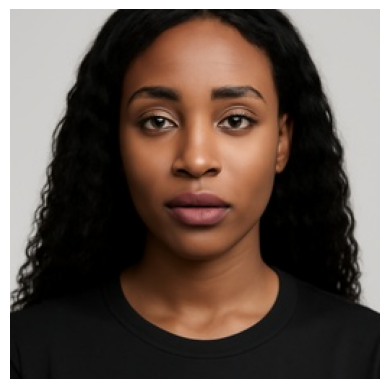

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(image)
plt.axis('off')
plt.show()